# ELEC70143 In-Class Exercise — Air Pollution Monitoring (CO prediction)

Target: `CO(GT)` (mg/m³). Data: `q1.csv`.

## Running this notebook on Windows or macOS

Follow the notebook setup in `README.md` and select the project's `.venv` Python
interpreter as the notebook kernel. Restart the kernel, then run all cells in order.
Install dependencies in the terminal before starting the kernel; installing or
upgrading NumPy inside a running kernel can leave incompatible modules loaded.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.model_selection import train_test_split, KFold, cross_val_score, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

RANDOM_STATE = 42
TARGET = "CO(GT)"

In [2]:
from pathlib import Path

# Find the shared project data from the project folder or a subfolder.
DATA_PATH = next(
    (root / "data" / "q1.csv" for root in (Path.cwd(), *Path.cwd().parents)
     if (root / "data" / "q1.csv").is_file()),
    None,
)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Cannot find data/q1.csv. Open this notebook from the project folder."
    )
df = pd.read_csv(DATA_PATH)
FEATURES = [c for c in df.columns if c != TARGET]

SENSOR_COST = {
    "PT08.S1(CO)": 1000,
    "PT08.S2(NMHC)": 800,
    "PT08.S3(NOx)": 700,
    "PT08.S4(NO2)": 700,
    "PT08.S5(O3)": 900,
    "T": 150,
    "RH": 150,
    "AH": 200,
    "NOx(GT)": 1800,
    "NO2(GT)": 1800,
    "C6H6(GT)": 2500,
}

df.head()


,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,2.6,1360.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,2.0,1292.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,2.2,1402.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,2.2,1376.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,1.6,1272.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


## A. Missing data

- Report % missing per feature
- Propose and justify a strategy, then implement it

,missing %
NO2(GT),5.42
NOx(GT),5.38
PT08.S1(CO),4.30
C6H6(GT),4.30
PT08.S5(O3),4.30
PT08.S2(NMHC),4.30
PT08.S3(NOx),4.30
PT08.S4(NO2),4.30
RH,4.30
T,4.30


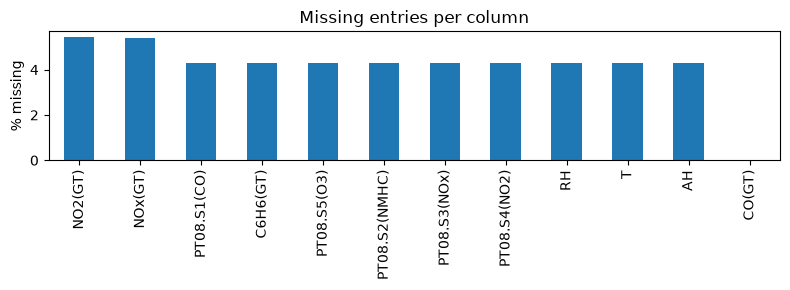

,n_rows,% rows
(none),6941,90.45
"NOx(GT), NO2(GT)",400,5.21
"PT08.S1(CO), C6H6(GT), PT08.S2(NMHC), PT08.S3(NOx), PT08.S4(NO2), PT08.S5(O3), T, RH, AH",317,4.13
"PT08.S1(CO), C6H6(GT), PT08.S2(NMHC), NOx(GT), PT08.S3(NOx), NO2(GT), PT08.S4(NO2), PT08.S5(O3), T, RH, AH",13,0.17
NO2(GT),3,0.04


Number of missing values per row:


0     6941
1        3
2      400
9      317
11      13
Name: count, dtype: int64

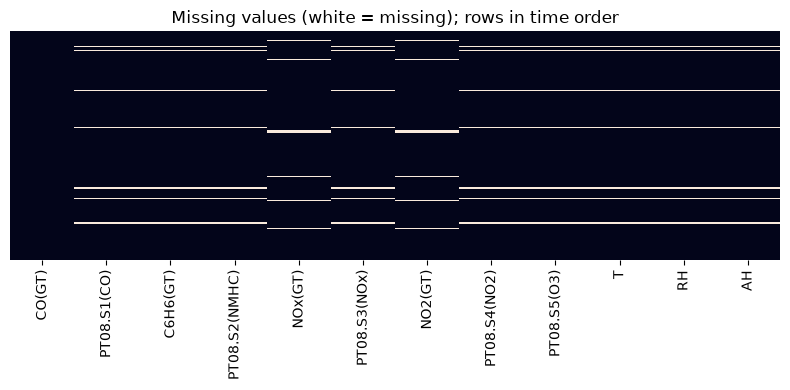

Device-offline rows: 330 in 13 contiguous blocks; longest block = 75 rows, median = 9 rows


,offline rows,other rows
count,330.000,7344.000
mean,2.665,2.130
std,1.710,1.436
min,0.300,0.100
25%,1.500,1.100
50%,2.200,1.800
75%,3.500,2.800
max,9.300,11.900
P(CO>5),0.100,0.042


Dropped 330 rows (4.30%); remaining = 7344


NOx(GT)    5.45
NO2(GT)    5.49
dtype: float64

Remaining NaNs after imputation: 0


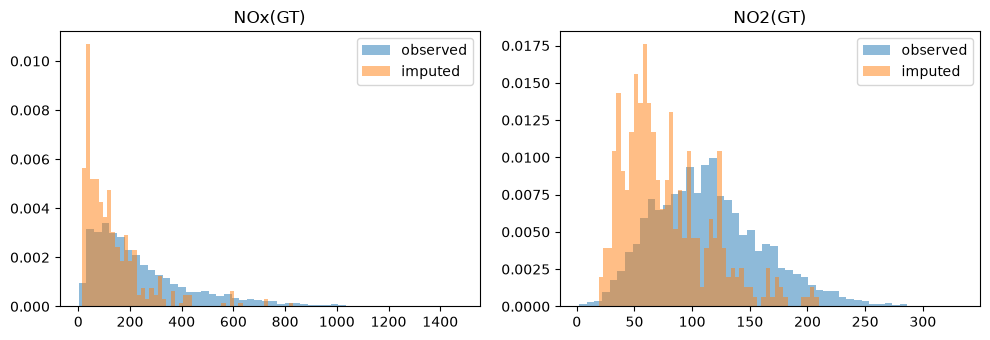

,before (observed),after (all rows)
NOx(GT),250.6,243.9
NO2(GT),113.9,111.9


In [3]:
# CELL1
missing_pct = df.isna().mean() * 100
missing_tbl = missing_pct.round(2).sort_values(ascending=False).to_frame("missing %")
display(missing_tbl)

missing_pct.sort_values(ascending=False).plot.bar(figsize=(8, 3))
plt.ylabel("% missing")
plt.title("Missing entries per column")
plt.tight_layout()
plt.show()

# CELL2
mask = df.isna()

pattern = mask.apply(lambda row: ", ".join(row[row].index) if row.any() else "(none)", axis=1)
pattern_counts = pattern.value_counts().to_frame("n_rows")
pattern_counts["% rows"] = (pattern_counts["n_rows"] / len(df) * 100).round(2)
display(pattern_counts)

print("Number of missing values per row:")
display(mask.sum(axis=1).value_counts().sort_index())


# CELL3
plt.figure(figsize=(8, 4))
sns.heatmap(mask, cbar=False, yticklabels=False)
plt.title("Missing values (white = missing); rows in time order")
plt.tight_layout()
plt.show()

offline = mask[FEATURES].sum(axis=1) >= 9          # all sensors + T/RH/AH missing
block_id = (offline != offline.shift()).cumsum()    # new id whenever the state changes
block_len = block_id[offline].value_counts()
print(f"Device-offline rows: {offline.sum()} in {len(block_len)} contiguous blocks; "
      f"longest block = {block_len.max()} rows, median = {int(block_len.median())} rows")

# CELL4
compare = pd.DataFrame({
    "offline rows": df.loc[offline, TARGET].describe(),
    "other rows": df.loc[~offline, TARGET].describe(),
})
compare.loc["P(CO>5)"] = [(df.loc[offline, TARGET] > 5).mean(), (df.loc[~offline, TARGET] > 5).mean()]
display(compare.round(3))

# CELL5
df_clean = df.loc[~offline].reset_index(drop=True)
print(f"Dropped {offline.sum()} rows ({offline.mean()*100:.2f}%); remaining = {len(df_clean)}")
display((df_clean.isna().mean() * 100).round(2)[lambda s: s > 0])

# CELL6
from sklearn.impute import KNNImputer

def knn_impute(fit_df, *other_dfs, cols=FEATURES, k=5):
    """Fit scaler + KNNImputer on fit_df[cols] only, then impute fit_df and any other_dfs.
    Scaling first because KNN uses Euclidean distance. The target is NOT used,
    since it would not be available at prediction time."""
    scaler = StandardScaler().fit(fit_df[cols])              # NaNs are ignored when fitting
    imputer = KNNImputer(n_neighbors=k).fit(scaler.transform(fit_df[cols]))

    out = []
    for d in (fit_df,) + other_dfs:
        d = d.copy()
        filled = imputer.transform(scaler.transform(d[cols]))
        d[cols] = scaler.inverse_transform(filled)           # back to original units
        out.append(d)
    return out[0] if len(out) == 1 else out

# For EDA (part B) we impute on the full cleaned data.
# NOTE: for modelling (part C onwards) refit the imputer on the TRAINING set only:
#   train_imp, test_imp = knn_impute(train_df, test_df)
df_imp = knn_impute(df_clean)
print("Remaining NaNs after imputation:", df_imp.isna().sum().sum())


# CELL7
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, col in zip(axes, ["NOx(GT)", "NO2(GT)"]):
    was_missing = df_clean[col].isna()
    ax.hist(df_clean[col].dropna(), bins=50, density=True, alpha=0.5, label="observed")
    ax.hist(df_imp.loc[was_missing, col], bins=50, density=True, alpha=0.5, label="imputed")
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "before (observed)": df_clean[["NOx(GT)", "NO2(GT)"]].mean(),
    "after (all rows)": df_imp[["NOx(GT)", "NO2(GT)"]].mean(),
}).round(1))

**Discussion (A):**


## B. Distributions & correlations

- Correlation plot / pairs plot of main features + target
- Comment on strong correlations and multicollinearity

**Discussion (B):**


## C. Train/test split & OLS

- 80/20 random split
- statsmodels OLS with all features, summary, significant variables
- Why are some coefficients huge / p-values large?

**Discussion (C):**


## D. Ridge & Lasso (CV-tuned, scaled features)

- Tune regularisation parameter by CV
- Coefficient paths vs. regularisation parameter (log scale)
- Effect on multicollinearity and interpretability

**Discussion (D):**


## E. Performance comparison

- In-sample and out-of-sample R², MAE, RMSE for OLS / Ridge / Lasso
- Pros and cons: performance vs. interpretability

**Discussion (E):**


## F. Cost–accuracy frontier

- Lasso path over a grid (e.g. 1e-6 to 1)
- For each: selected features, total cost, 5-fold CV RMSE on training data
- Plot Cost vs. RMSE
- Low-cost design (≤ £2500) and high-performance design (≤ £4000); test-set RMSE

**Discussion (F):**


## G. Alert threshold

- Legal threshold y = 5 mg/m³; FP = £2,000, FN = £10,000
- Alert if prediction > t; expected cost vs. t via CV
- Choose a threshold

In [4]:
CO_LIMIT = 5.0
COST_FP = 2000
COST_FN = 10000


**Discussion (G):**


## H. Low-cost vs. high-performance: expected cost

- Compare expected cost of the two designs
- Are the extra sensors justified?

**Discussion (H):**
